In [1]:
import jax
import jax.numpy as jnp

from hcnn.constraint.constraint_state_outside_sphere import ConstraintStateOutsideSphere
from hcnn.environment import Environment
from hcnn.policy.policy_lqr import PolicyLQR
from hcnn.system.system_linear import SystemLinear

center = jnp.array([1, 1])
radius = 1.25

state_matrix = jnp.array([[1, -1], [1, 0]])
input_matrix = jnp.array([[1.0], [0.0]])
state_cost = jnp.eye(2)
input_cost = jnp.eye(1)
system = SystemLinear.factory(state_matrix, input_matrix)
policy = PolicyLQR.factory(system, state_cost, input_cost)
constraint = ConstraintStateOutsideSphere.factory(center=center, radius=radius)
environment = Environment.factory(system, policy, constraint)

In [2]:
policy

PolicyLQR(state_cost=Array([[1., 0.],
       [0., 1.]], dtype=float32), input_cost=Array([[1.]], dtype=float32), riccati_matrix=Array([[ 3.1301594, -0.6101485],
       [-0.6101485,  1.7578782]], dtype=float32), gain_matrix=Array([[ 0.61014867, -0.75787866]], dtype=float32))

In [3]:
view_range = 3.0
samples_per_axis = 20
axis_samples = jnp.linspace(-view_range, view_range, samples_per_axis)
X, Y = jnp.meshgrid(axis_samples, axis_samples, indexing="xy")
states = jnp.stack((X.flatten(), Y.flatten()), axis=-1)
test = environment.step(jnp.array([1.0, 2.0]))
next_states = jax.vmap(environment.step, in_axes=(0))(states)
difference = next_states - states

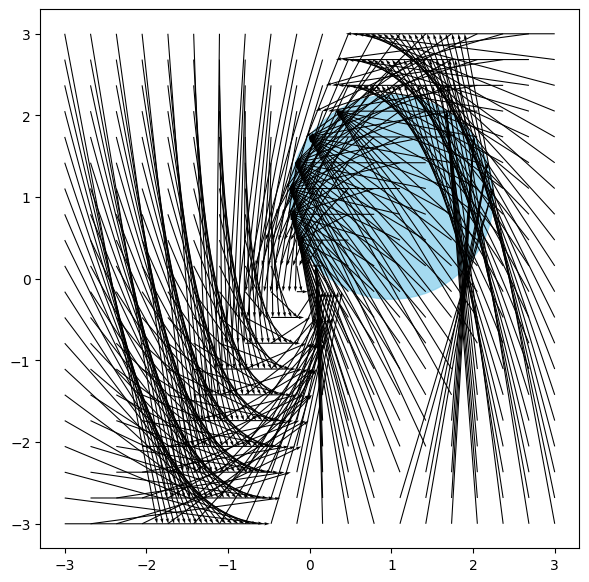

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 7), dpi=100)
ax.set_aspect("equal")
circle = plt.Circle(center, radius, color="skyblue", alpha=0.75, label="constraint")
ax.add_artist(circle)
plt.quiver(
    states[:, 0],
    states[:, 1],
    difference[:, 0],
    difference[:, 1],
    angles="xy",
    scale_units="xy",
    scale=1,
    width=0.002,
)
plt.show()

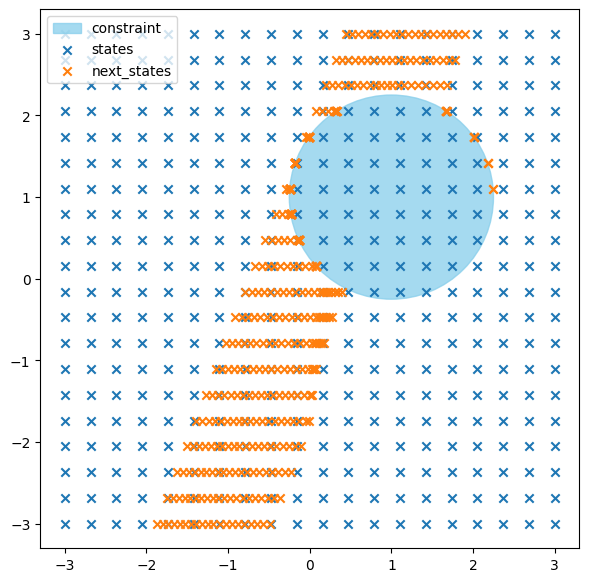

In [5]:
fig, ax = plt.subplots(figsize=(7, 7), dpi=100)
ax.set_aspect("equal")
circle = plt.Circle(center, radius, color="skyblue", alpha=0.75, label="constraint")
ax.add_artist(circle)
plt.scatter(states[:, 0], states[:, 1], marker="x", label="states")
plt.scatter(next_states[:, 0], next_states[:, 1], marker="x", label="next_states")
plt.legend()
plt.show()

In [6]:
from hcnn.optimization.problem_policy_deviation import ProblemPolicyDeviation
from hcnn.optimization.solver_linearize import SolverLinearize

problem = ProblemPolicyDeviation.factory(
    system=system,
    policy=policy,
    constraint=constraint,
    horizon=10,
    rho=20,
).copy_with(initial_state=jnp.array([1.0, -1.0]))

problem.pretty_print(problem.x0)
print("cost", problem.cost_fun(problem.x0))
# print("lb", jnp.all(problem.lower_bound - 1e-6 <= problem.constraints(problem.x0)))
# print("ub", jnp.all(problem.constraints(problem.x0) <= problem.upper_bound + 1e-6))

actions [[-1.3680273e+00]
 [ 3.7228137e-01]
 [ 4.7636300e-01]
 [ 9.5573477e-02]
 [-7.8078195e-02]
 [-5.3579271e-02]
 [-1.9835520e-03]
 [ 1.2199394e-02]
 [ 5.2362108e-03]
 [-9.1239013e-04]]
policy_actions [[-1.3680273e+00]
 [ 3.7228137e-01]
 [ 4.7636300e-01]
 [ 9.5573477e-02]
 [-7.8078195e-02]
 [-5.3579271e-02]
 [-1.9835520e-03]
 [ 1.2199394e-02]
 [ 5.2362108e-03]
 [-9.1239013e-04]]
states [[ 1.         -1.        ]
 [ 0.6319727   1.        ]
 [ 0.00425404  0.6319727 ]
 [-0.15135562  0.00425404]
 [-0.06003619 -0.15135562]
 [ 0.01324124 -0.06003619]
 [ 0.01969816  0.01324124]
 [ 0.00447337  0.01969816]
 [-0.0030254   0.00447337]
 [-0.00226255 -0.0030254 ]]
relaxations [[0.       ]
 [1.4270558]
 [0.4355458]
 [0.       ]
 [0.       ]
 [0.       ]
 [0.       ]
 [0.       ]
 [0.       ]
 [0.       ]]
abs_relaxations [[0.       ]
 [1.4270558]
 [0.4355458]
 [0.       ]
 [0.       ]
 [0.       ]
 [0.       ]
 [0.       ]
 [0.       ]
 [0.       ]]
cost 18.626017


In [7]:
x_star = SolverLinearize.solve(problem)
problem.pretty_print(x_star)
print("cost", problem.cost_fun(x_star))

actions [[-2.2509189 ]
 [ 0.91100186]
 [ 0.01722181]
 [-0.21385787]
 [-0.08754329]
 [ 0.01764826]
 [ 0.02807882]
 [ 0.00667203]
 [-0.00419763]
 [-0.00325131]]
policy_actions [[-1.367997  ]
 [ 0.9110003 ]
 [ 0.01722186]
 [-0.213858  ]
 [-0.08754439]
 [ 0.0176494 ]
 [ 0.02807884]
 [ 0.00667175]
 [-0.00419773]
 [-0.00325119]]
states [[ 1.0000213e+00 -9.9992824e-01]
 [-2.5095370e-01  1.0000165e+00]
 [-3.3995566e-01 -2.5096431e-01]
 [-7.1769513e-02 -3.3996060e-01]
 [ 5.4334052e-02 -7.1772285e-02]
 [ 3.8559780e-02  5.4331049e-02]
 [ 1.8772207e-03  3.8561024e-02]
 [-8.6039007e-03  1.8765378e-03]
 [-3.8087962e-03 -8.6052222e-03]
 [ 5.9948716e-04 -3.8079736e-03]]
relaxations [[-2.5635918e-05]
 [ 1.4763256e-05]
 [ 3.9122992e-06]
 [-3.8908502e-06]
 [-1.9990994e-06]
 [ 4.9837595e-06]
 [ 1.9813654e-06]
 [-3.4975420e-07]
 [-3.6165042e-07]
 [ 2.7324131e-06]]
abs_relaxations [[ 2.1593252e-13]
 [ 9.3516734e-14]
 [-1.7958629e-15]
 [ 1.9518871e-15]
 [ 1.7125738e-15]
 [ 8.0444911e-16]
 [ 2.1361365e-14]
 [

cost 0.38977548
lb True
ub True


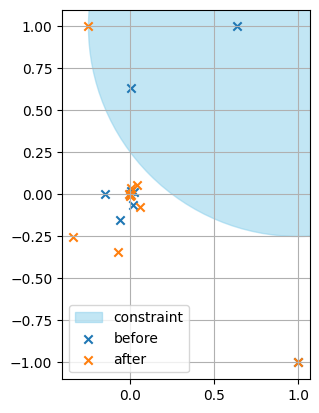

In [8]:
print("cost", problem.cost_fun(x_star))
print("lb", jnp.all(problem.lower_bound - 1e-2 <= problem.constraints(x_star)))
print("ub", jnp.all(problem.constraints(x_star) <= problem.upper_bound + 1e-2))


optvar_star = problem.debug_optvar(x_star)
optvar_0 = problem.debug_optvar(problem.x0)

# Create figure and axis
fig, ax = plt.subplots()
circle = plt.Circle(center, radius, color="skyblue", alpha=0.5, label="constraint")
ax.add_artist(circle)
plt.scatter(optvar_0.states[:, 0], optvar_0.states[:, 1], marker="x", label="before")
plt.scatter(optvar_star.states[:, 0], optvar_star.states[:, 1], marker="x", label="after")
ax.set_aspect("equal")
plt.legend()
plt.grid(True)
plt.show()